# Simple and multiple regression: energy, market and oil

Monthly US energy-sector excess returns for **2011–2025** are regressed on the
market, then on the market and Brent price changes. The analysis compares
coefficient interpretation, uncertainty and model fit on the same sample.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorise Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.

In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

- **Energy:** total return on the value-weighted US energy-sector portfolio from the
  [Kenneth French industry data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_12_ind_port.html).
- **Market:** broad value-weighted US CRSP equity-market return minus RF (`Mkt-RF`),
  from the [French factor data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html).
  **RF** is the matched monthly risk-free return.
- **Brent:** last available monthly [EIA/FRED spot price](https://fred.stlouisfed.org/series/DCOILBRENTEU);
  its percentage change is not a futures return.

Subtract RF from Energy; Market is already an excess return. Variables are converted
from decimals to **percent**: one unit is one percentage point. December 2010 supplies
the initial Brent price; both regressions use the following **180 months**.

In [3]:
data = pd.read_csv(DATA_DIR / "monthly_energy_market_data.csv", parse_dates=["date"])
data = data.set_index("date").sort_index()

returns = pd.DataFrame({
    "Energy": 100 * (data["Energy"] - data["RF"]),
    "Market": 100 * data["Market_excess"],
    "Brent": 100 * data["Brent_spot"].pct_change(fill_method=None),
}).loc["2011-01-01":"2025-12-31"]

if returns.isna().any().any():
    raise ValueError("Missing observations: check the data before comparing the models.")
print(f"Estimation sample: {returns.index[0]:%Y-%m} to {returns.index[-1]:%Y-%m}; {len(returns)} months")
display(returns.head().round(3))

Estimation sample: 2011-01 to 2025-12; 180 months


,Energy,Market,Brent
date,,,
2011-01-31,6.92,1.98,6.157
2011-02-28,7.62,3.48,13.438
2011-03-31,2.10,0.45,4.160
2011-04-30,1.58,2.90,8.252
2011-05-31,-4.51,-1.27,-7.433


## Simple regression: the market model

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+u_t.$$

**Alpha** is fitted energy excess return when Market is zero. **Beta** is its change,
in percentage points, for a one-percentage-point increase in Market.
This CAPM-style regression uses a sector portfolio; CAPM reasoning also applies
to individual stocks. Estimating the regression alone does not validate the CAPM.

Both models use OLS coefficients and **Newey–West HAC standard errors with three
monthly lags**. HAC allows heteroskedasticity and short-run serial dependence;
it changes estimated uncertainty, not coefficients or fitted values.

In [4]:
y = returns["Energy"]
# Newey–West HAC: Bartlett weights, three monthly lags and a sample-size correction.
# The t reference used for robust inference is an approximation, not an exact test.
HAC_OPTIONS = {"maxlags": 3, "kernel": "bartlett", "use_correction": True}

X_simple = sm.add_constant(returns[["Market"]])
simple = sm.OLS(y, X_simple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     35.97
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.09e-08
Time:                        14:11:17   Log-Likelihood:                -577.72
No. Observations:                 180   AIC:                             1159.
Df Residuals:                     178   BIC:                             1166.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.6295      0.576     -1.093      0.2

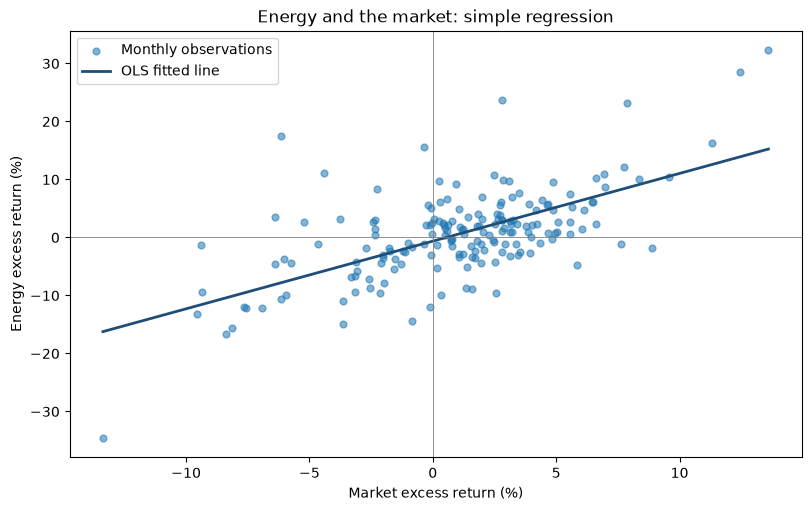

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.scatter(returns["Market"], y, s=24, alpha=0.55, label="Monthly observations")
market_grid = np.linspace(returns["Market"].min(), returns["Market"].max(), 100)
ax.plot(market_grid, simple.params["const"] + simple.params["Market"] * market_grid,
        color="#1F4E79", lw=2, label="OLS fitted line")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set(xlabel="Market excess return (%)", ylabel="Energy excess return (%)",
       title="Energy and the market: simple regression")
ax.legend()
plt.show()

The **standard error** measures uncertainty about a coefficient, not return volatility.
The reported statistic is $t=\hat\theta/SE(\hat\theta)$, testing
$H_0:\theta=0$ against $H_1:\theta\ne0$; for beta, this is not a test of beta = 1.

Under the null and test assumptions, the **p-value** is the probability of a statistic
at least as extreme as observed. It is not the probability that the null is true.
At 5%, reject when $p<0.05$; a Type I error is rejecting a true null.
A displayed `0.000` is rounding. The 95% interval excludes zero exactly when the
matching two-sided 5% test rejects. HAC inference is approximate.

## Multiple regression: adding Brent

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+\beta_O\Delta p^{Brent}_t+u_t.$$

$\Delta p^{Brent}_t$ is the monthly percentage change in the spot price.
Each slope now measures a change in fitted Energy **holding the other regressor
constant**. Alpha corresponds to both regressors being zero.
Adding Brent gives an extended return regression, rather than the one-factor CAPM.
The coefficients describe partial associations, rather than established causal effects.

In [6]:
X_multiple = sm.add_constant(returns[["Market", "Brent"]])
multiple = sm.OLS(y, X_multiple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     50.03
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           6.01e-18
Time:                        14:11:18   Log-Likelihood:                -555.78
No. Observations:                 180   AIC:                             1118.
Df Residuals:                     177   BIC:                             1127.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4757      0.486     -0.979      0.3

### Interpreting the slopes

The panels show fitted Energy as Market varies with Brent fixed at zero, and as
Brent varies with Market fixed at zero. Both lines pass through alpha.
A ten-percentage-point increase in Brent contributes $10\hat\beta_O$ percentage
points to fitted Energy. Horizontal scales differ, so the numerical coefficients
measure the slopes. Plotting ranges are illustrative; estimation uses all 180 months.

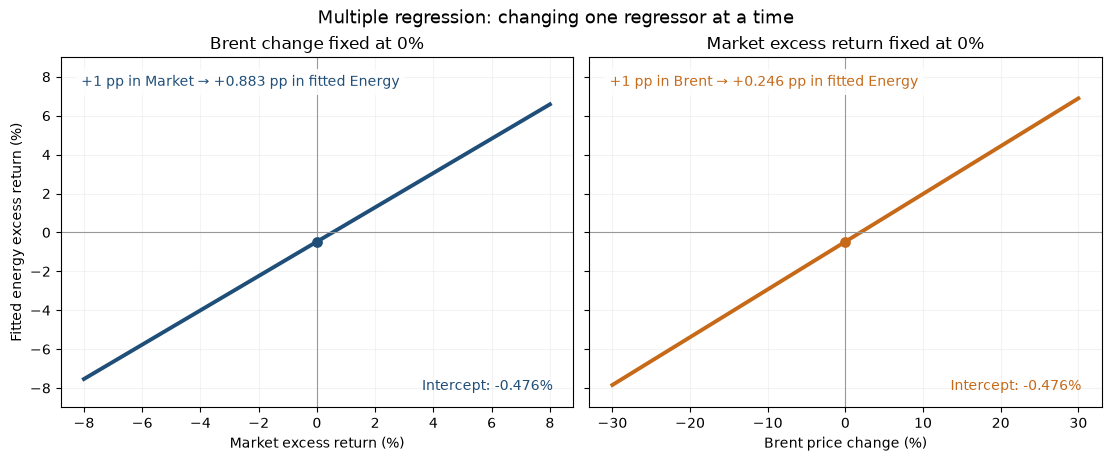

In [7]:
alpha = multiple.params["const"]
beta_market = multiple.params["Market"]
beta_brent = multiple.params["Brent"]
market_grid = np.linspace(-8, 8, 100)
brent_grid = np.linspace(-30, 30, 100)
market_colour, brent_colour = "#1F4E79", "#C66A19"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True,
                         constrained_layout=True)
panels = [
    (axes[0], market_grid, alpha + beta_market * market_grid,
     market_colour, "Market excess return (%)", "Brent change fixed at 0%",
     beta_market, "Market"),
    (axes[1], brent_grid, alpha + beta_brent * brent_grid,
     brent_colour, "Brent price change (%)", "Market excess return fixed at 0%",
     beta_brent, "Brent"),
]
for ax, grid, fitted, colour, xlabel, title, beta, name in panels:
    ax.plot(grid, fitted, color=colour, lw=2.8)
    ax.scatter([0], [alpha], color=colour, s=45, zorder=3)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.grid(alpha=0.15)
    ax.set(xlabel=xlabel, title=title, ylim=(-9, 9))
    ax.text(0.04, 0.95, f"+1 pp in {name} → {beta:+.3f} pp in fitted Energy",
            transform=ax.transAxes, va="top", fontsize=10, color=colour,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
    ax.text(0.96, 0.05, f"Intercept: {alpha:.3f}%",
            transform=ax.transAxes, ha="right", color=colour, fontsize=10)
axes[0].set_ylabel("Fitted energy excess return (%)")
fig.suptitle("Multiple regression: changing one regressor at a time", fontsize=13)
plt.show()

### The regression plane

The same slopes appear in 3D: **blue** varies Market with Brent fixed at zero;
**orange** varies Brent with Market fixed at zero. The surface shows fitted returns.
Observations are omitted to keep the plane visible.

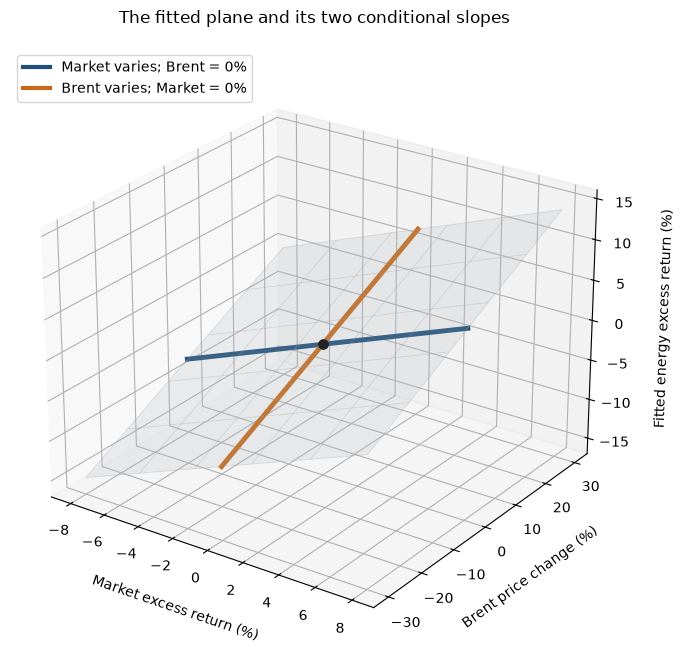

In [8]:
from matplotlib.lines import Line2D

market_mesh, brent_mesh = np.meshgrid(market_grid, brent_grid)
energy_mesh = alpha + beta_market * market_mesh + beta_brent * brent_mesh

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(market_mesh, brent_mesh, energy_mesh,
                color="#B9C4CE", alpha=0.20, linewidth=0)
ax.plot_wireframe(market_mesh, brent_mesh, energy_mesh,
                  rstride=20, cstride=20, color="0.65", alpha=0.35, linewidth=0.6)
ax.plot(market_grid, np.zeros_like(market_grid),
        alpha + beta_market * market_grid, color=market_colour, lw=3.5)
ax.plot(np.zeros_like(brent_grid), brent_grid,
        alpha + beta_brent * brent_grid, color=brent_colour, lw=3.5)
ax.scatter([0], [0], [alpha], color="black", s=45, depthshade=False)
ax.set_xlabel("Market excess return (%)", labelpad=10)
ax.set_ylabel("Brent price change (%)", labelpad=10)
ax.set_zlabel("Fitted energy excess return (%)", labelpad=10)
ax.set_title("The fitted plane and its two conditional slopes", pad=18)
ax.set_box_aspect((1.2, 1.2, 0.9))
ax.view_init(elev=25, azim=-55)
ax.legend(handles=[
    Line2D([], [], color=market_colour, lw=3, label="Market varies; Brent = 0%"),
    Line2D([], [], color=brent_colour, lw=3, label="Brent varies; Market = 0%"),
], loc="upper left", fontsize=10)
fig.subplots_adjust(left=0.02, right=0.87, bottom=0.05, top=0.92)
plt.show()

## Comparing the models

The table compares coefficients, HAC standard errors and fit on the same sample.
Residual SD measures unexplained return variation, in percentage points.

The plots compare **observed and fitted returns**. Multiple-model fitted values use
both regressors; points on the 45-degree line have observed return equal to fitted return.

In [9]:
models = {"Market only": simple, "Market + Brent": multiple}
comparison = pd.DataFrame({
    name: {"Observations": int(model.nobs),
           "Alpha (% per month)": model.params["const"],
           "Market beta": model.params["Market"],
           "SE: market beta": model.bse["Market"],
           "R-squared": model.rsquared,
           "Adjusted R-squared": model.rsquared_adj,
           "Residual SD (pp)": np.sqrt(model.mse_resid)}
    for name, model in models.items()
})
display(comparison.round(4))
print(f"Market–Brent sample correlation: {returns['Market'].corr(returns['Brent']):.3f}")

,Market only,Market + Brent
Observations,180.0000,180.0000
Alpha (% per month),-0.6295,-0.4757
Market beta,1.1672,0.8825
SE: market beta,0.1946,0.1787
R-squared,0.4010,0.5306
Adjusted R-squared,0.3977,0.5253
Residual SD (pp),6.0268,5.3503


Market–Brent sample correlation: 0.394


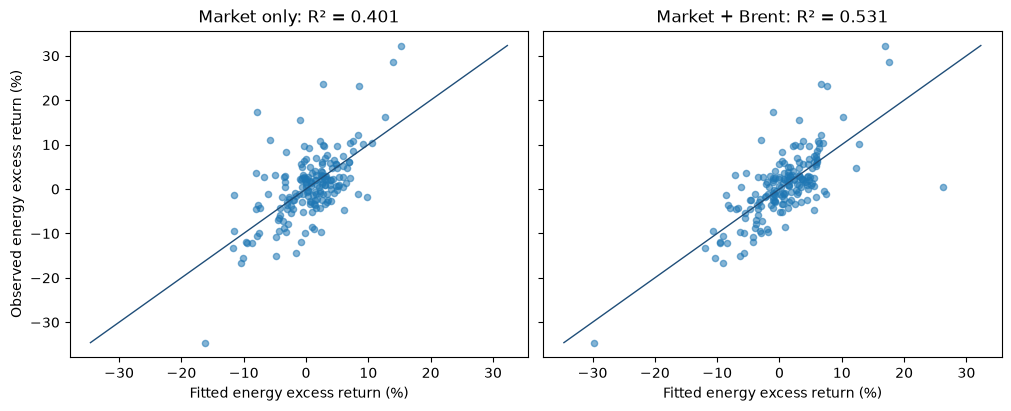

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         constrained_layout=True)
limits = [min(y.min(), *(m.fittedvalues.min() for m in models.values())),
          max(y.max(), *(m.fittedvalues.max() for m in models.values()))]
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(model.fittedvalues, y, s=20, alpha=0.55)
    ax.plot(limits, limits, color="#1F4E79", lw=1)
    ax.set(title=f"{name}: R² = {model.rsquared:.3f}",
           xlabel="Fitted energy excess return (%)")
axes[0].set_ylabel("Observed energy excess return (%)")
plt.show()

$R^2$ is the fraction of sample return variation explained by the model.
Adding Brent cannot lower in-sample $R^2$; adjusted $R^2$ penalises extra regressors.
Better fit does not establish causality or guarantee better forecasts.

Brent's association with Energy and correlation with Market help explain the change
in market beta, linking the comparison to **omitted variable bias**. HAC standard
errors do not remove this bias; robust inference is examined in a later tutorial.